# Failed Login Detector

A Python script that scans server logs for brute-force login attempts.

## What it does
- Reads a server log file
- Counts failed login attempts per IP address
- Flags any IP that exceeds a configurable threshold
- Visualizes the results in a bar chart

## Tools used
Python, matplotlib, Google Colab, Claude (AI assistant, used for guidance and code explanations)

## What I learned
I learned how to parse log data with Python and count events per IP address. Changing the alert threshold showed me the tradeoff between catching real attacks and generating false alarms.

## Future improvements
- Track failures within a time window (for example, 5 failures in 1 minute)
- Detect one IP trying many different usernames
- Handle real log formats like Linux auth.log


In [1]:
log = """2026-10-30 09:01:12 LOGIN_FAILED user=admin ip=203.0.113.5
2026-10-30 09:01:15 LOGIN_FAILED user=admin ip=203.0.113.5
2026-10-30 09:01:18 LOGIN_FAILED user=root ip=203.0.113.5
2026-10-30 09:02:03 LOGIN_SUCCESS user=maria ip=198.51.100.7
2026-10-30 09:02:40 LOGIN_FAILED user=admin ip=203.0.113.5
2026-10-30 09:03:11 LOGIN_FAILED user=jake ip=192.0.2.44
2026-10-30 09:03:15 LOGIN_SUCCESS user=jake ip=192.0.2.44
2026-10-30 09:03:50 LOGIN_FAILED user=root ip=203.0.113.5
2026-10-30 09:04:22 LOGIN_FAILED user=admin ip=203.0.113.5
2026-10-30 09:05:01 LOGIN_SUCCESS user=dana ip=198.51.100.9"""

lines = log.split("\n")
print("Total log entries:", len(lines))
print("First entry:", lines[0])


Total log entries: 10
First entry: 2026-10-30 09:01:12 LOGIN_FAILED user=admin ip=203.0.113.5


In [8]:
failed_counts = {}

for line in lines:
    if "LOGIN_FAILED" in line:
        ip = line.split("ip=")[1]
        failed_counts[ip] = failed_counts.get(ip, 0) + 1

print(failed_counts)


{'203.0.113.5': 6, '192.0.2.44': 1}


In [9]:
THRESHOLD = 5

for ip, count in failed_counts.items():
    if count >= THRESHOLD:
        print("ALERT: possible brute-force attack from", ip, "with", count, "failed logins")
    else:
        print("OK:", ip, "had", count, "failed login(s)")


ALERT: possible brute-force attack from 203.0.113.5 with 6 failed logins
OK: 192.0.2.44 had 1 failed login(s)


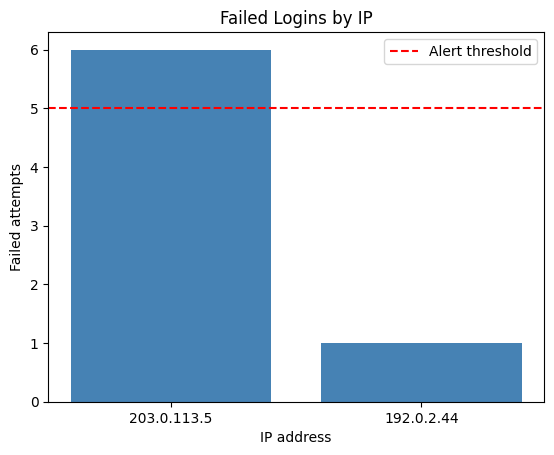

In [10]:
import matplotlib.pyplot as plt

ips = list(failed_counts.keys())
counts = list(failed_counts.values())

plt.bar(ips, counts, color="steelblue")
plt.axhline(y=THRESHOLD, color="red", linestyle="--", label="Alert threshold")
plt.title("Failed Logins by IP")
plt.xlabel("IP address")
plt.ylabel("Failed attempts")
plt.legend()
plt.show()


In [7]:
# Save our log to a file (simulating a real log file)
with open("server.log", "w") as f:
    f.write(log)

# Now read it back the way a real script would
with open("server.log", "r") as f:
    lines = f.read().strip().split("\n")

print("Loaded", len(lines), "entries from file")


Loaded 10 entries from file
